In [ ]:
#Import necessary libraries
import tensorflow as tf
from tensorflow.keras import datasets , layers , models
import matplotlib . pyplot as plt

# Load the MNIST dataset
( train_images , train_labels ) , ( test_images , test_labels ) =datasets.mnist.load_data ()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
# Preprocess the data
# Reshape the dataset to include a channel dimension ( needed for CNN )
train_images = train_images . reshape (( train_images . shape [0] , 28 , 28 , 1) )
test_images = test_images . reshape (( test_images . shape [0] , 28 , 28 , 1) )

In [ ]:
# Normalize the pixel values to be between 0 and 1
train_images , test_images = train_images / 255.0 , test_images / 255.0

In [ ]:
# Define the CNN model
model = models . Sequential ([
layers . Conv2D (32 , (3 , 3) , activation ='relu', input_shape =(28 , 28 ,1) ) ,
layers . MaxPooling2D ((2 , 2) ) ,
layers . Conv2D (64 , (3 , 3) , activation ='relu') ,
layers . MaxPooling2D ((2 , 2) ) ,
layers . Conv2D (64 , (3 , 3) , activation ='relu') ,
layers . Flatten () ,
layers . Dense (64 , activation ='relu') ,
layers . Dense (10 , activation ='softmax')])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
#Compile the model
model . compile ( optimizer ='adam',loss ='sparse_categorical_crossentropy',
metrics =['accuracy'])

In [ ]:
#Train the model
history = model . fit ( train_images , train_labels , epochs =5 ,
validation_data =( test_images , test_labels ) )

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 6ms/step - accuracy: 0.9538 - loss: 0.1466 - val_accuracy: 0.9865 - val_loss: 0.0466
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.9858 - loss: 0.0455 - val_accuracy: 0.9894 - val_loss: 0.0349
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9902 - loss: 0.0314 - val_accuracy: 0.9891 - val_loss: 0.0354
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9920 - loss: 0.0258 - val_accuracy: 0.9874 - val_loss: 0.0414
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9941 - loss: 0.0192 - val_accuracy: 0.9889 - val_loss: 0.0386


In [ ]:
# Evaluate the model on test data
test_loss , test_acc = model . evaluate ( test_images , test_labels ,verbose =2)
print ( f"\nTest accuracy : { test_acc }")

313/313 - 1s - 3ms/step - accuracy: 0.9889 - loss: 0.0386

Test accuracy : 0.9889000058174133


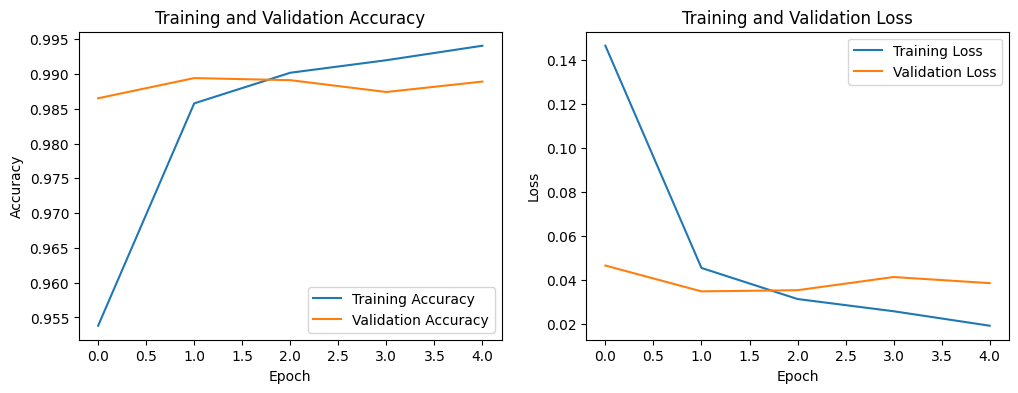

In [14]:
# Plot training history ( accuracy & loss )
plt.figure(figsize =(12 , 4))
plt.subplot(1 , 2 , 1)
plt.plot(history.history ['accuracy'] , label ='Training Accuracy')
plt.plot(history.history ['val_accuracy'] , label ='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend( loc ='lower right')
plt.title('Training and Validation Accuracy')
plt.subplot(1 , 2 , 2)
plt.plot( history.history ['loss'] , label ='Training Loss')
plt.plot( history.history ['val_loss'] , label ='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend ( loc ='upper right')
plt.title ('Training and Validation Loss')
plt.show ()